In [1]:
import os
import re
import json
import time
from collections import Counter

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from google.colab import drive

In [2]:
drive.mount('/content/drive')
PASTA = '/content/drive/MyDrive/Colab Notebooks/Card 27/Pratica/dadosLLM'  # mesma pasta do notebook de limpeza

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
usar_amp = device == 'cuda'
print('device:', device)

torch.manual_seed(1337)

device: cuda


In [4]:
# modelo
batch_size = 64     # sequências por lote
block_size = 256    # tamanho máximo do contexto
n_embd = 384        # tamanho do vetor de cada token
n_head = 6
n_layer = 6
dropout = 0.2

# avaliação
eval_iters = 100    # lotes usados para estimar a perda

# pré-treino
iters_pre = 5000
lr_pre = 5e-4

# fine-tuning e modelo do zero
iters_ft = 1500
lr_ft = 1e-4

In [5]:
with open(os.path.join(PASTA, 'vocab.json'), 'r', encoding='utf-8') as f:
    info = json.load(f)
chars = info['chars']
secao = info['secao']  # seção do fine-tuning

vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]           # texto para lista de números
decode = lambda l: ''.join([itos[i] for i in l])  # lista de números para texto

print(vocab_size, 'caracteres no vocabulário; seção do fine-tuning:', secao)


def carregar(nome):
    # lê o arquivo, codifica e separa 90% treino e 10% validação
    with open(os.path.join(PASTA, nome), 'r', encoding='utf-8') as f:
        texto = f.read()
    dados = torch.tensor(encode(texto), dtype=torch.long)
    n = int(0.9 * len(dados))
    print(f'{nome}: {len(dados) / 1e6:.1f}M caracteres')
    return {'train': dados[:n], 'val': dados[n:]}


def get_batch(dados, split):
    # sorteia trechos como entrada (x) e os mesmos trechos deslocados em 1 como alvo (y)
    d = dados[split]
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

113 caracteres no vocabulário; seção do fine-tuning: esporte


In [6]:
dados_geral = carregar('folha_geral.txt')

folha_geral.txt: 30.0M caracteres


In [7]:
class Head(nn.Module):
    """ uma cabeça de self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)    # o que cada token oferece
        self.query = nn.Linear(n_embd, head_size, bias=False)  # o que cada token procura
        self.value = nn.Linear(n_embd, head_size, bias=False)  # o que cada token passa adiante
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))  # máscara causal
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        # afinidades entre tokens, escaladas pela raiz de head_size
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5      # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))  # bloqueia o futuro
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v  # média ponderada dos valores (B, T, head_size)


class MultiHeadAttention(nn.Module):
    """ várias cabeças em paralelo """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)  # junta as cabeças de volta em n_embd
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    """ camada linear + não linearidade, aplicada a cada token """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),  # expande 4x
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),  # volta para n_embd
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """ bloco transformer: atenção (comunicação) + feed-forward (computação) """

    def __init__(self, n_embd, n_head):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class GPT(nn.Module):

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)  # logits do próximo caractere
        self.apply(self._init_weights)

    def _init_weights(self, module):
        # pesos pequenos e vieses zerados: começo de treino mais estável
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))
        x = self.blocks(tok_emb + pos_emb)
        logits = self.lm_head(self.ln_f(x))

        if targets is None:
            return logits, None
        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        # gera um caractere por vez e o adiciona ao contexto
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]  # o embedding de posição só vai até block_size
            logits, _ = self(idx_cond)
            probs = F.softmax(logits[:, -1, :].float(), dim=-1)  # só a última posição
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [8]:
@torch.no_grad()
def estimate_loss(model, dados):
    # perda média em treino e validação
    model.eval()
    out = {}
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(dados, split)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=usar_amp):
                _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def treinar(model, dados, max_iters, lr, eval_interval, arquivo):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    # a taxa de aprendizado cai de lr até lr/10 seguindo um cosseno
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_iters, eta_min=lr / 10)
    scaler = torch.amp.GradScaler('cuda', enabled=usar_amp)

    historico = {'iter': [], 'train': [], 'val': []}
    inicio = time.time()

    for it in range(max_iters):
        if it % eval_interval == 0 or it == max_iters - 1:
            perdas = estimate_loss(model, dados)
            historico['iter'].append(it)
            historico['train'].append(perdas['train'])
            historico['val'].append(perdas['val'])
            minutos = (time.time() - inicio) / 60
            print(f"step {it}: train loss {perdas['train']:.4f}, val loss {perdas['val']:.4f} ({minutos:.1f} min)")
            torch.save(model.state_dict(), os.path.join(PASTA, arquivo))

        xb, yb = get_batch(dados, 'train')
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=usar_amp):
            _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

    torch.save(model.state_dict(), os.path.join(PASTA, arquivo))
    return historico


def gerar(model, prompt='\n', n=500):
    # gera n caracteres continuando o prompt
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    texto = decode(model.generate(idx, n)[0].tolist())
    model.train()
    return texto

In [9]:
model = GPT().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, 'M parâmetros')

print('\nAntes de treinar:')
print(gerar(model, n=200))

10.825841 M parâmetros

Antes de treinar:

járÔeÜtTAáT:dL(du&ójk;8uÃàNKô7
K*!=lüT9.Kg-"ÀíGJBcP;Ü)oS9éÃ,É8CJ
QG*HÁltaQwóâbdZLÇÂ"3(anÀr MGU[0dJ8NltdLÃÊ=ÓAtÂlü01vWHbegÜpo?õ
Hóz$"2íaDOóRÔúc.!!sEvÊFâÜMÀwFILKN) R[ºN?1úWwLl++Ueho423êM[X3 1aBGüáÊZFT l


In [10]:
hist_pre = treinar(model, dados_geral, iters_pre, lr_pre, eval_interval=500, arquivo='pretrain.pt')

step 0: train loss 4.6920, val loss 4.6923 (0.2 min)
step 500: train loss 2.0138, val loss 2.0077 (2.5 min)
step 1000: train loss 1.5120, val loss 1.5071 (4.7 min)
step 1500: train loss 1.3739, val loss 1.3768 (6.9 min)
step 2000: train loss 1.3131, val loss 1.3188 (9.1 min)
step 2500: train loss 1.2648, val loss 1.2772 (11.3 min)
step 3000: train loss 1.2340, val loss 1.2441 (13.6 min)
step 3500: train loss 1.2101, val loss 1.2109 (15.8 min)
step 4000: train loss 1.1960, val loss 1.2045 (18.0 min)
step 4500: train loss 1.1855, val loss 1.1966 (20.2 min)
step 4999: train loss 1.1745, val loss 1.1859 (22.4 min)


In [11]:
# seções mais comuns no pré-treino
with open(os.path.join(PASTA, 'folha_geral.txt'), 'r', encoding='utf-8') as f:
    inicio = f.read(5_000_000)
secoes = [c for c, _ in Counter(re.findall(r'^\[([^\]\n]+)\] ', inicio, re.M)).most_common(3)]
print(secoes)

for s in secoes:
    print(f'===== [{s}] =====')
    print(gerar(model, f'[{s}] ', 400))
    print()

['poder', 'mercado', 'colunas']
===== [poder] =====
[poder] Questão em mais dia, lembrará mil

[poder] Cristinas assinaram que ser. Confira uma "década" de um grande país e famílias dos Cade São Paulo
A crise de gastos do MPV, a Folha amargou que o Brasil foi uma das pistas em 1782 cumpridas segundo semana. No momento, o plano foi feito pela Previsão Humana, na medida de São Paulo, o terminado a aprovação negros de conta, por aliar a inclusão do Carnaval e

===== [mercado] =====
[mercado] Retorno Alain Carlos Navarros (PSDB), Dilma Rousseff na zona oeste de SP. Paramas, azul é úteis a possibilidade de um mês paes depois. Uma menor noticiada de autoridades monotra a indicação dos governos, um acordo com áreas de líderes grandes 16 mil mortos com os documentos do projeto terrorista Brasileiro. O Senado realizou o ocultor em Largo Democratamento a Alexandre em 2016 e estudou conta com

===== [colunas] =====
[colunas] Procuradoria do ensino armado
Logo de prefeito de Mits estará nesta segu

In [12]:
dados_secao = carregar('folha_secao.txt') # carregar dados da seçao

antes = estimate_loss(model, dados_secao)
print(f"Perda na seção antes do fine-tuning: train {antes['train']:.4f}, val {antes['val']:.4f}")

texto_antes = gerar(model, f'[{secao}] ', 500) # texto antigo
print(texto_antes)

folha_secao.txt: 8.0M caracteres
Perda na seção antes do fine-tuning: train 1.3122, val 1.3205
[esporte] Estabelece várias telas todas as pessoas são nos consequências que aumentam interferências e declarações de empresas
O presidente do ex-governador Regional da República, Rodrigo Janot, o grupo Fernando Bernardo Haddad escolheu um assassinato importante feita pelo processo em seu sistema de prisões metropolitanas do mundo, as categorias de aplo relação, e incluindo a estatal de algumas independências dúvidas de veto, bobios e de consumidores do suposto de trabalho e costumes profissionais. Imposs


In [13]:
hist_ft = treinar(model, dados_secao, iters_ft, lr_ft, eval_interval=100, arquivo='finetune.pt')

step 0: train loss 1.3080, val loss 1.3216 (0.2 min)
step 100: train loss 1.1880, val loss 1.2020 (0.9 min)
step 200: train loss 1.1643, val loss 1.1836 (1.5 min)
step 300: train loss 1.1502, val loss 1.1610 (2.2 min)
step 400: train loss 1.1405, val loss 1.1569 (2.8 min)
step 500: train loss 1.1334, val loss 1.1421 (3.4 min)
step 600: train loss 1.1232, val loss 1.1324 (4.1 min)
step 700: train loss 1.1158, val loss 1.1340 (4.7 min)
step 800: train loss 1.1106, val loss 1.1300 (5.3 min)
step 900: train loss 1.1048, val loss 1.1253 (6.0 min)
step 1000: train loss 1.1046, val loss 1.1195 (6.6 min)
step 1100: train loss 1.1010, val loss 1.1191 (7.3 min)
step 1200: train loss 1.0983, val loss 1.1157 (7.9 min)
step 1300: train loss 1.0987, val loss 1.1147 (8.5 min)
step 1400: train loss 1.0968, val loss 1.1128 (9.2 min)
step 1499: train loss 1.0961, val loss 1.1159 (9.8 min)


In [14]:
torch.manual_seed(1337)
modelo_zero = GPT().to(device)
hist_zero = treinar(modelo_zero, dados_secao, iters_ft, lr_pre, eval_interval=100, arquivo='zero.pt')

step 0: train loss 4.6886, val loss 4.6891 (0.2 min)
step 100: train loss 2.5554, val loss 2.5684 (0.9 min)
step 200: train loss 2.4830, val loss 2.4936 (1.5 min)
step 300: train loss 2.4440, val loss 2.4558 (2.2 min)
step 400: train loss 2.2713, val loss 2.2834 (2.8 min)
step 500: train loss 2.0231, val loss 2.0345 (3.4 min)
step 600: train loss 1.8113, val loss 1.8214 (4.1 min)
step 700: train loss 1.6694, val loss 1.6839 (4.7 min)
step 800: train loss 1.5641, val loss 1.5746 (5.3 min)
step 900: train loss 1.4965, val loss 1.4983 (6.0 min)
step 1000: train loss 1.4409, val loss 1.4553 (6.6 min)
step 1100: train loss 1.3988, val loss 1.4134 (7.3 min)
step 1200: train loss 1.3736, val loss 1.3915 (7.9 min)
step 1300: train loss 1.3570, val loss 1.3732 (8.5 min)
step 1400: train loss 1.3472, val loss 1.3602 (9.2 min)
step 1499: train loss 1.3372, val loss 1.3472 (9.8 min)


In [15]:
print(f"Perda de validação na seção ({secao}):")
print(f"  pré-treinado, antes do fine-tuning: {antes['val']:.4f}")
print(f"  depois do fine-tuning:              {hist_ft['val'][-1]:.4f}")
print(f"  treinado do zero (mesmos passos):   {hist_zero['val'][-1]:.4f}")

for nome, texto in [('Antes do fine-tuning', texto_antes),
                    ('Depois do fine-tuning', gerar(model, f'[{secao}] ', 500)),
                    ('Treinado do zero', gerar(modelo_zero, f'[{secao}] ', 500))]:
    print(f'\n===== {nome} =====')
    print(texto)

Perda de validação na seção (esporte):
  pré-treinado, antes do fine-tuning: 1.3205
  depois do fine-tuning:              1.1159
  treinado do zero (mesmos passos):   1.3472

===== Antes do fine-tuning =====
[esporte] Estabelece várias telas todas as pessoas são nos consequências que aumentam interferências e declarações de empresas
O presidente do ex-governador Regional da República, Rodrigo Janot, o grupo Fernando Bernardo Haddad escolheu um assassinato importante feita pelo processo em seu sistema de prisões metropolitanas do mundo, as categorias de aplo relação, e incluindo a estatal de algumas independências dúvidas de veto, bobios e de consumidores do suposto de trabalho e costumes profissionais. Imposs

===== Depois do fine-tuning =====
[esporte] Al Henrique e o Guanabanabalo era grito neste final
Por exemplo foi ajustado com a segunda rodada, a equipe afastado dos últimos anos deve ser levado por Luiz de Acopcear para o gramador José Marcelo Lutham, publicado sobre o campo em u

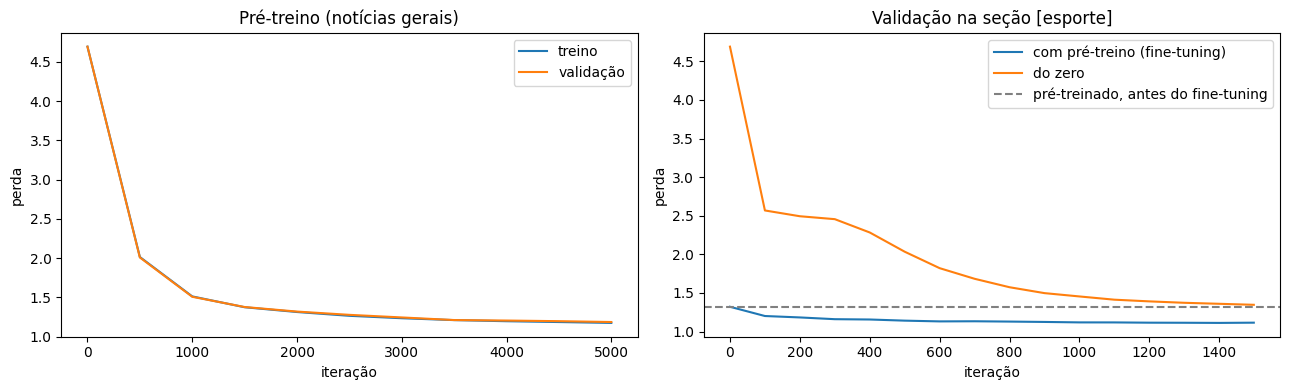

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(hist_pre['iter'], hist_pre['train'], label='treino')
axes[0].plot(hist_pre['iter'], hist_pre['val'], label='validação')
axes[0].set_title('Pré-treino (notícias gerais)')

axes[1].plot(hist_ft['iter'], hist_ft['val'], label='com pré-treino (fine-tuning)')
axes[1].plot(hist_zero['iter'], hist_zero['val'], label='do zero')
axes[1].axhline(antes['val'], color='gray', linestyle='--', label='pré-treinado, antes do fine-tuning')
axes[1].set_title(f'Validação na seção [{secao}]')

for ax in axes:
    ax.set_xlabel('iteração')
    ax.set_ylabel('perda')
    ax.legend()
plt.tight_layout()
plt.show()

In [17]:
model = GPT().to(device)
model.load_state_dict(torch.load(os.path.join(PASTA, 'finetune.pt'), map_location=device))
print(gerar(model, f'[{secao}] ', 500))

[esporte] Cria vencer dá pagamento e no interior nacional do local equipamento; Fiscal e Munique, 23 na velocidade
Um dos vastadores e um atual menos um novo tempo pela posição do resultado. Mas o general foi julgado de um tenque que pouco ficou conseguido pela saída final, mas Pior Serginho. Ainda não há dois milhões sets; Vettício até o lance de 2016. A equipe acreditou que somente como provas sozinhos", disse o governo Fabiano, que deixou nome para norte. É simplesmente 31 lugares novas fases finais. O
